# Prueba Intertrimestral

**Nombre:**  Paula
**Apellidos:**  Bonet Sánchez

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime, timedelta, date
import json

# Visualización (Matplotlib, Seaborn y Plotly)
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Estadística y Machine Learning (Scikit-Learn)
from scipy import stats
from scipy.stats import ttest_ind
import sklearn.datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression, ElasticNet
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    silhouette_score
)

sns.set_theme(style="whitegrid")

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [2]:
def rental_fee(duracion_min, bike_type, is_member):
    
    if bike_type == "classic":
        tarifa_base=1.00
        coste_min=0.05
        
    elif bike_type== "electric":
        tarifa_base=1.50
        coste_min=0.08
    else: 
        raise ValueError()
    
    total = tarifa_base + coste_min*duracion_min
    
    if is_member:
        total = 0.2*total
        
    return round(total,2)

print(rental_fee(20,"classic",False))
print(rental_fee(20,"classic",True))
print(rental_fee(20,"electric",False))
print(rental_fee(20,"electric",True))

2.0
0.4
3.1
0.62


b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [3]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:
        return "Alta"
    elif threshold / 2 <= total_rentals < threshold:
        return "Media"
    else:
        return "Baja"
    
demand_label(50,45)

'Alta'

c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [4]:
data = {
    "duration_min": [10.0, 25.5, 40.0, 12.0, 55.0, 18.0, 30.0, 47.0, 60.0, 22.5],
    "bike_type": ["classic", "electric", "classic", "electric", "classic", "electric", "classic", "electric", "classic", "electric"],
    "is_member": [False, True, False, True, False, False, True, True, False, True],
}

tripsDemo = pd.DataFrame(data)

tripsDemo["fee"] = tripsDemo.apply(
    lambda row: rental_fee(row["duration_min"], row["bike_type"], row["is_member"]),
    axis=1
)

tripsDemo["total_rentals"] = [15, 90, 42, 120, 70, 35, 55, 110, 95, 60]

tripsDemo["demand"] = tripsDemo["total_rentals"].apply(
    lambda x: demand_label(x, threshold=40)
)

print(tripsDemo)

   duration_min bike_type  is_member   fee  total_rentals demand
0          10.0   classic      False  1.50             15   Baja
1          25.5  electric       True  0.71             90   Alta
2          40.0   classic      False  3.00             42   Alta
3          12.0  electric       True  0.49            120   Alta
4          55.0   classic      False  3.75             70   Alta
5          18.0  electric      False  2.94             35  Media
6          30.0   classic       True  0.50             55   Alta
7          47.0  electric       True  1.05            110   Alta
8          60.0   classic      False  4.00             95   Alta
9          22.5  electric       True  0.66             60   Alta


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [28]:
class MicromobilityTools:

    def __init__(self):
        self.df = pd.DataFrame()
    def rental_fee(duracion_min, bike_type, is_member):

        if bike_type == "classic":
            tarifa_base=1.00
            coste_min=0.05

        elif bike_type== "electric":
            tarifa_base=1.50
            coste_min=0.08
        else: 
            raise ValueError()

        total = tarifa_base + coste_min*duracion_min

        if is_member:
            total = 0.2*total

        return round(total,2)
    def demand_label(total_rentals, threshold):
        if total_rentals >= threshold:
            return "Alta"
        elif threshold / 2 <= total_rentals < threshold:
            return "Media"
        else:
            return "Baja"

    def generar_dataframe(self, lista_x, lista_y):
        self.df = pd.DataFrame({'col1': lista_x, 'col2': lista_y})
        self.df['res_1a'] = self.df.apply(lambda r: self.funcion_1a(r['col1'], r['col2']), axis=1)
        self.df['res_1b'] = self.df['res_1a'].apply(self.funcion_1b)
        return self.df
    #mi_objeto = MicromobilityTools()
#display(mi_objeto.generar_dataframe([70, "classic",True], [50, 45]).head())

ValueError: arrays must all be same length

## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [6]:

mobilityData = pd.read_csv("city_micromobility_hourly.csv")
mobilityData.head()

,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [14]:
def describeData(dataFrame):
    resumen = pd.DataFrame({
        'Tipo_Dato': mobilityData.dtypes,
        'Nulos_Totales': mobilityData.isna().sum(),
        'Porcentaje_Nulos (%)': (mobilityData.isna().sum() / len(mobilityData) * 100).round(2),
        'Valores_Unicos': mobilityData.nunique()
    })
    print(f"Dimensiones (filas, columnas): {mobilityData.shape} | Duplicados: {mobilityData.duplicated().sum()}")
    return resumen

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [15]:
describeData(mobilityData)

Dimensiones (filas, columnas): (17520, 23) | Duplicados: 0


,Tipo_Dato,Nulos_Totales,Porcentaje_Nulos (%),Valores_Unicos
datetime,object,0,0.00,17520
year,int64,0,0.00,2
month,int64,0,0.00,12
day,int64,0,0.00,31
hour,int64,0,0.00,24
weekday,int64,0,0.00,7
season,object,0,0.00,4
is_holiday,int64,0,0.00,2
is_weekend,int64,0,0.00,2
is_workingday,int64,0,0.00,2


In [16]:
def load_and_check_missing(filepath):
    # Cargar el archivo CSV
    df = pd.read_csv(filepath)

    # Verificar valores faltantes
    missing_info = df.isnull().sum()
    missing_values = missing_info[missing_info > 0]

    # Mostrar el resultado
    if missing_values.empty:
        print("No hay valores faltantes en el dataset.")
    else:
        print("Valores faltantes encontrados:")
        print(missing_values)
        # Eliminar filas con valores faltantes
        df = df.dropna()
        print("Registros con valores faltantes eliminados.")
    return df

df_clean = load_and_check_missing('city_micromobility_hourly.csv')

    

Valores faltantes encontrados:
humidity          224
wind_kmh          142
avg_trip_min      255
electric_share    182
dtype: int64
Registros con valores faltantes eliminados.


d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


In [36]:
import seaborn as sns
import matplotlib.pyplot as plt


# 1. Seleccionar solo las columnas numéricas
numeric_df = df_clean.select_dtypes(include=[np.number])


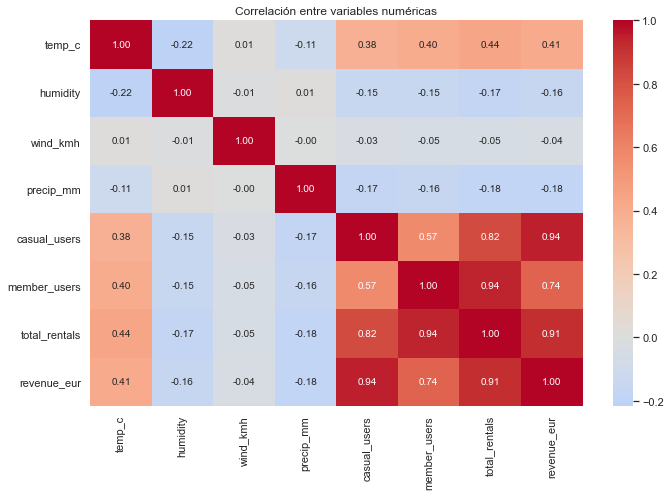

Correlaciones con total_rentals:
member_users    0.935529
revenue_eur     0.914631
casual_users    0.822913
temp_c          0.440550
precip_mm      -0.181480
humidity       -0.169431
wind_kmh       -0.047837
Name: total_rentals, dtype: float64


In [35]:
variables = ["temp_c", "humidity", "wind_kmh", "precip_mm",
    "casual_users", "member_users", "total_rentals", "revenue_eur"]

variables_disponibles = [
    columna for columna in variables
    if columna in mobilityData.columns
    and pd.api.types.is_numeric_dtype(mobilityData[columna])
]

correlaciones = mobilityData[variables_disponibles].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

if "total_rentals" in correlaciones.columns:
    print("Correlaciones con total_rentals:")
    print(
        correlaciones["total_rentals"]
        .drop("total_rentals")
        .sort_values(key=abs, ascending=False)
    )


La temperatura tienen una fuerte relacion con la cantidad de bicis que se utilizan. A mayores temperaturas, mas bicis se usan. Lo demás tienen que ver con el dinero que reciben, a mas uso, mas dinero. Las correlaciones negativas son con la humedad, si hay mas humaded, se usan menos bicis. 

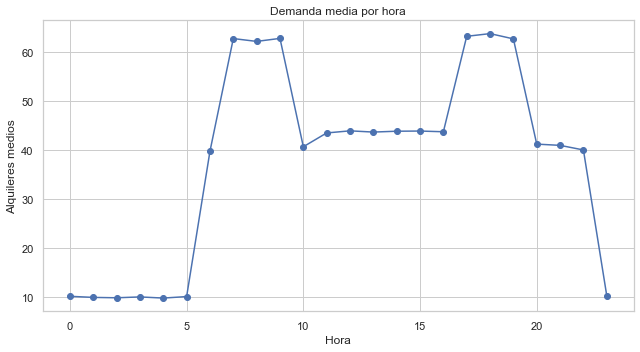

Hora punta: 18
Demanda media en hora punta: 63.82


In [34]:
demanda_hora = (
    mobilityData.groupby("hour")["total_rentals"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(9, 5))
plt.plot(demanda_hora.index, demanda_hora.values, marker="o")
plt.title("Demanda media por hora")
plt.xlabel("Hora")
plt.ylabel("Alquileres medios")
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Hora punta: {demanda_hora.idxmax()}")
print(f"Demanda media en hora punta: {demanda_hora.max():.2f}")

La demanda es mucho más alta por las mañanas antes de ir a trabajar y por las terdes al salir de trabajar.

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [20]:

cols_x = ['hour', 'temp_c', 'humidity', 'wind_kmh', 'precip_mm']
X = df_clean[cols_x]
y = df_clean['total_rentals'] 


print(f"Variable Objetivo (y): {y}")
print(f"Variables Predictoras (X): {X}")

Variable Objetivo (y): 0        10
1         6
2         5
3        12
4         5
         ..
17515    55
17516    22
17517    24
17518    38
17519     7
Name: total_rentals, Length: 16738, dtype: int64
Variables Predictoras (X):        hour  temp_c  humidity  wind_kmh  precip_mm
0         0    6.39      67.1       9.7        0.0
1         1    4.88      37.2       2.8        0.0
2         2    1.72      79.7       9.0        0.0
3         3   -3.40      51.4       5.4        0.0
4         4    8.24      82.2       2.4        0.0
...     ...     ...       ...       ...        ...
17515    19    4.76      67.8       1.9        0.0
17516    20    9.53      55.7      15.8        0.0
17517    21   10.43      70.4       4.1        0.0
17518    22    9.05      56.5       1.4        0.0
17519    23   12.36      77.8       8.3        0.0

[16738 rows x 5 columns]


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.3, # 30% para prueba
        random_state=42 # Semilla para reproducibilidad
    )

print(f"Conjunto original (X_new): {X.shape[0]} registros.")
print("\nDimensiones de los conjuntos:")
print(f"X_train (70%): {X_train.shape}")
print(f"X_test (30%): {X_test.shape}")
print(f"y_train (70%): {y_train.shape}")
print(f"y_test (30%): {y_test.shape}")

Conjunto original (X_new): 16738 registros.

Dimensiones de los conjuntos:
X_train (70%): (11716, 5)
X_test (30%): (5022, 5)
y_train (70%): (11716,)
y_test (30%): (5022,)


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

lm = LinearRegression()

lm.fit(X_train, y_train)

y_pred = lm.predict(X_test)

# Calcular el R² (Coeficiente de Determinación)
r2 = r2_score(y_test, y_pred)

# Calcular el MSE (Mean Squared Error)
mse = mean_squared_error(y_test, y_pred)

print("Evaluación del Modelo de Regresión Lineal")
print(f"R² (Coeficiente de Determinación): {r2:.4f}")
print(f"MSE (Error Cuadrático Medio): {mse:.4f}")

Evaluación del Modelo de Regresión Lineal
R² (Coeficiente de Determinación): 0.2926
MSE (Error Cuadrático Medio): 416.9542


El coeficiente de determinacion es bastante bajo por lo tantoel modelo no explica bien los datos. Random Forest tiene menor MSE porque coge relaciones no lineales e interacciones entre variables que la regresión lineal no ve. 

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [23]:
from sklearn.ensemble import RandomForestRegressor


rf = RandomForestRegressor(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

# Calcular el R²
r2_rf = r2_score(y_test, y_pred)

# Calcular el MSE
mse_rf = mean_squared_error(y_test, y_pred_rf)

print("--- Evaluación del Modelo Random Forest Regressor ---")
print(f"R² (Random Forest): {r2_rf:.4f}")
print(f"MSE (Random Forest): {mse_rf:.4f}")

--- Evaluación del Modelo Random Forest Regressor ---
R² (Random Forest): 0.2926
MSE (Random Forest): 119.9319


## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [24]:
df_clean.value_counts("high_demand")

high_demand
0    11527
1     5211
dtype: int64

b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Variables explicativas
X = df_clean[cols_x]

# Variable objetivo
y = df_clean["high_demand"]


# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Escalado
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Modelo
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# Predicción
y_pred = model.predict(X_test_scaled)

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


In [26]:

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nMatriz de confusión:\n", confusion_matrix(y_test, y_pred))
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred))

Accuracy: 0.736857825567503

Matriz de confusión:
 [[2077  229]
 [ 652  390]]

Reporte de clasificación:
               precision    recall  f1-score   support

           0       0.76      0.90      0.83      2306
           1       0.63      0.37      0.47      1042

    accuracy                           0.74      3348
   macro avg       0.70      0.64      0.65      3348
weighted avg       0.72      0.74      0.71      3348



d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



Parece ser que los factores que más influyen en la demanda de micromovilidad son la humedad, la temperatura y la hora. Con mas datos tendríamos mucha más iformacion teniendo que ver con la cantidad de bicicletas que se usan dpenediendo de donde se esta. HAbrá ciudades que por ejemplo tengas una mayor tolerancia a temperaturas más bajas y demas. 